# BrightMart Retail — Customer Analytics & Machine Learning

**Mini Project | Analytical Modelling with Machine Learning**

---
**Dataset:** `BrightMart_ML_Dataset.csv` — 648 synthetic retail customer records  
**Models:** Linear Regression · Decision Tree · K-Means · Random Forest  
**Author:** Aryan Koundal  
**Repository:** [koundal-aryan/BrightMart-customer-analytics-machine-learning](https://github.com/koundal-aryan/BrightMart-customer-analytics-machine-learning)


In [ ]:
# 1. Library Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
sns.set_style('whitegrid')
print("Libraries loaded.")

Libraries loaded.



### 2. Dataset Loading & Description

In [ ]:
dataset_path = 'BrightMart_ML_Dataset.csv'
df_raw = pd.read_csv(dataset_path)
print(f"Shape: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
print("\nFirst 5 rows:")
df_raw.head()

Shape: 648 rows x 10 columns

First 5 rows:


  Customer_ID  Age  Annual_Income  Spending_Score  Purchase_Frequency Discount_Usage  Ad_Spend   Sales Campaign_Response Customer_Segment
0       C0001   44          124.0              65                  17            Low     38.22   99.61               Yes          Premium
1       C0002   36           98.0              67                  18         Medium     73.28  157.25               Yes          Premium
2       C0003   46           60.2              14                   5           High     22.92   79.30                No          Regular
3       C0004   56          150.0              80                  18            Low     21.08   65.71               Yes          Premium
4       C0005   35           67.8              41                  14         Medium     39.38  103.15               Yes          Regular

### 3. Data Cleaning & Validation (Task A)

In [ ]:
# Check missing values
print("Missing values:")
print(df_raw.isnull().sum())
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")
print("\nDescriptive statistics:")
print(df_raw.describe().round(2))

Missing values:
Customer_ID           0
Age                   0
Annual_Income         0
Spending_Score        0
Purchase_Frequency    0
Discount_Usage        0
Ad_Spend              0
Sales                 0
Campaign_Response     0
Customer_Segment      0

Duplicate rows: 0

Descriptive statistics:
          Age  Annual_Income  Spending_Score  Purchase_Frequency  Ad_Spend   Sales
count  648.00         648.00          648.00              648.00    648.00  648.00
mean    38.02          71.80           51.56               13.18     51.91  122.76
std     11.34          24.48           20.89                3.70     24.74   47.20
min     18.00          24.00            1.00                2.00     10.02   24.39
25%     30.00          53.80           37.00               11.00     30.44   84.60
50%     38.00          67.90           52.50               13.00     50.96  120.56
75%     46.00          85.10           66.00               16.00     75.12  164.59
max     70.00         150.00        

In [ ]:
df_clean = df_raw.copy()
df_clean.dropna(inplace=True)
df_clean.drop_duplicates(inplace=True)
df_clean = df_clean[df_clean['Sales']       >  0]
df_clean = df_clean[df_clean['Ad_Spend']    >= 0]
df_clean = df_clean[df_clean['Annual_Income']>  0]
df_clean = df_clean[df_clean['Spending_Score'].between(1, 100)]
df_clean.reset_index(drop=True, inplace=True)

# Save cleaned dataset
df_clean[df_raw.columns].to_csv('BrightMart_ML_Dataset_Cleaned.csv', index=False)

print(f"Cleaned dataset: {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")
print(f"Missing values after cleaning: {df_clean.isnull().sum().sum()}")
print("Cleaned CSV saved: BrightMart_ML_Dataset_Cleaned.csv")

Cleaned dataset: 648 rows x 14 columns
Missing values after cleaning: 0
Cleaned CSV saved: BrightMart_ML_Dataset_Cleaned.csv


**Data Cleaning Decisions:**

| Check | Result |
|-------|--------|
| Missing values | **0** — no rows dropped for nulls |
| Duplicate rows | **0** — no duplicates found |
| Sales > 0 | All rows passed |
| Ad_Spend >= 0 | All rows passed |
| Annual_Income > 0 | All rows passed |
| Spending_Score 1–100 | All rows passed |
| **Rows kept** | **648 of 648** |

- 6 customers with `Annual_Income = 150` (at the data ceiling) were **kept** — these are valid high-income observations.
- **Class imbalance noted:** 69.8% of customers responded Yes to the campaign. This is handled by reporting **Precision, Recall and F1** alongside Accuracy, so the model is not misleadingly evaluated on accuracy alone.

### 4. Exploratory Data Analysis (EDA) — Task A

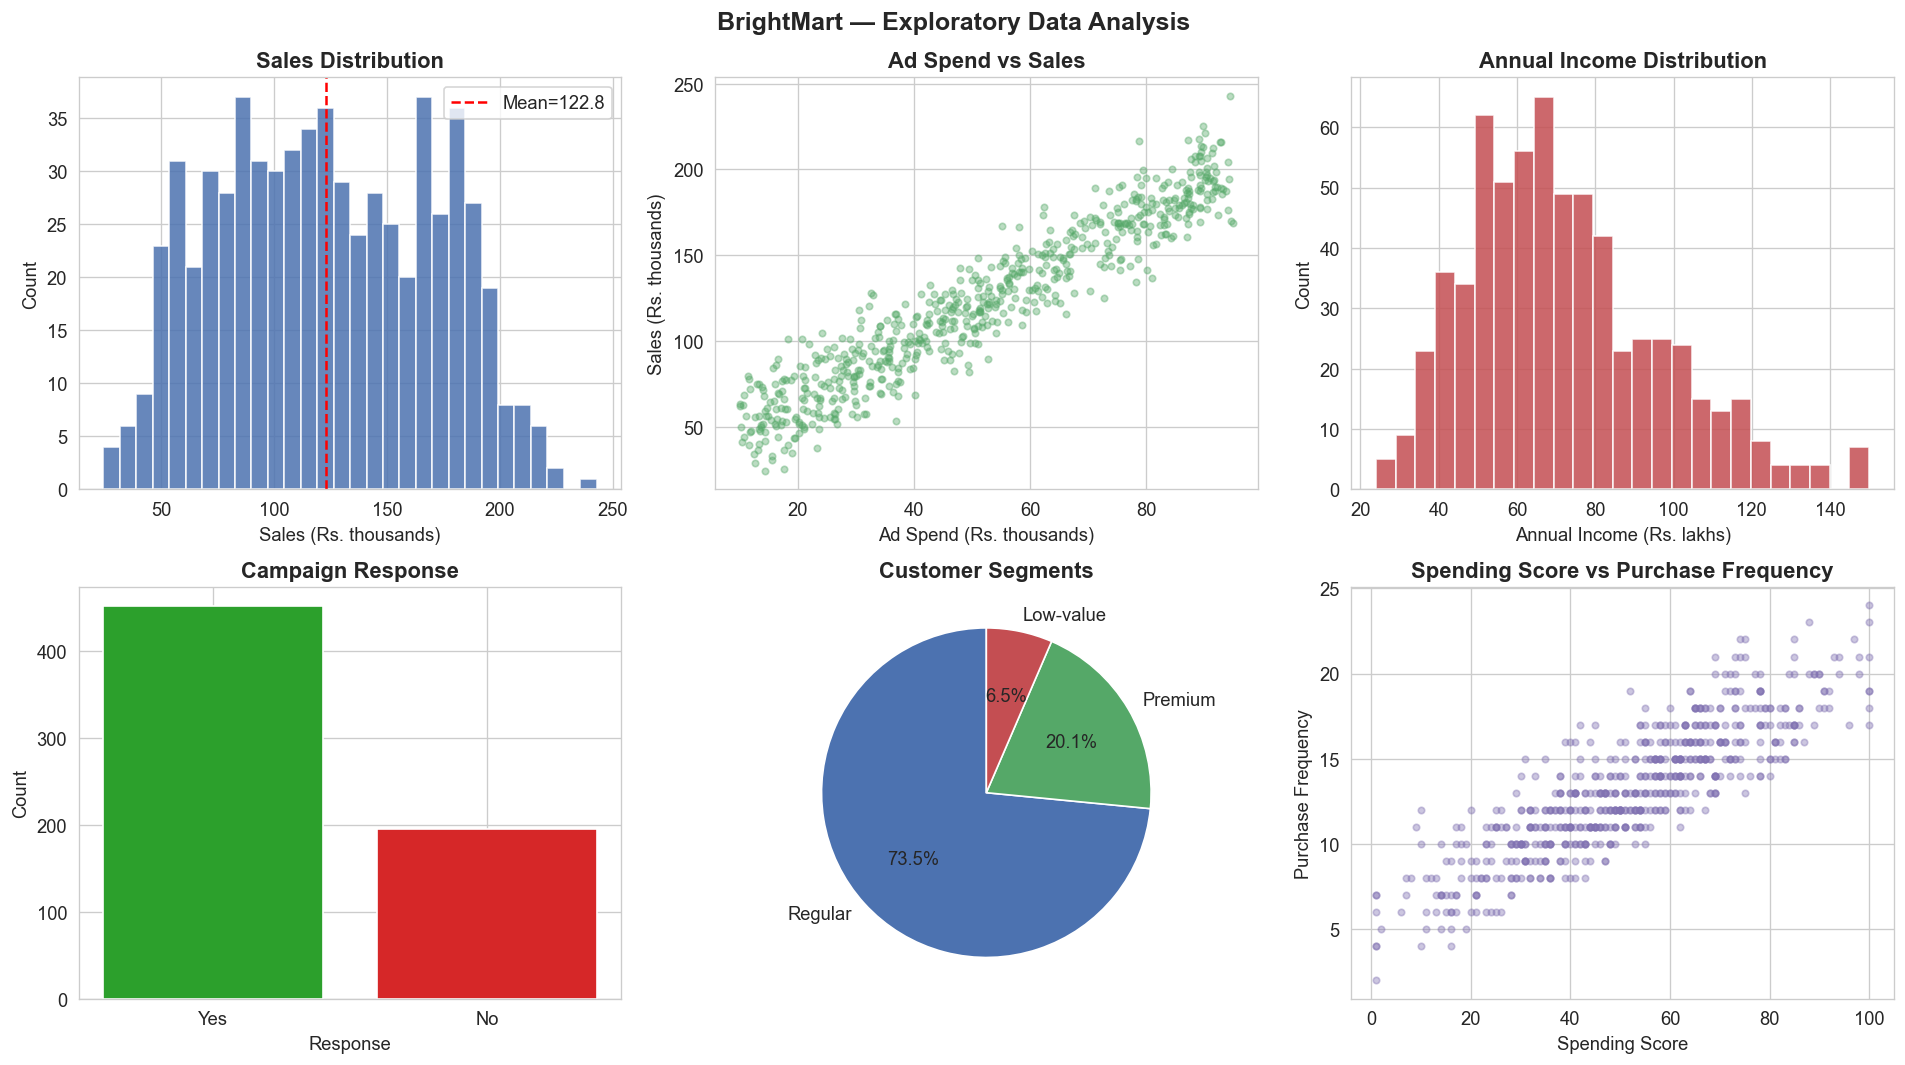

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('BrightMart — Exploratory Data Analysis', fontsize=15, fontweight='bold')

# (a) Sales distribution
axes[0,0].hist(df_clean['Sales'], bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
axes[0,0].axvline(df_clean['Sales'].mean(), color='red', linestyle='--', lw=1.5,
                  label=f"Mean={df_clean['Sales'].mean():.1f}")
axes[0,0].set_title('Sales Distribution', fontweight='bold')
axes[0,0].set_xlabel('Sales (Rs. thousands)'); axes[0,0].set_ylabel('Count')
axes[0,0].legend()

# (b) Ad Spend vs Sales — Task A viz 2
axes[0,1].scatter(df_clean['Ad_Spend'], df_clean['Sales'], alpha=0.4, color='#55A868', s=15)
axes[0,1].set_title('Ad Spend vs Sales', fontweight='bold')
axes[0,1].set_xlabel('Ad Spend (Rs. thousands)'); axes[0,1].set_ylabel('Sales (Rs. thousands)')

# (c) Annual Income
axes[0,2].hist(df_clean['Annual_Income'], bins=25, color='#C44E52', edgecolor='white', alpha=0.85)
axes[0,2].set_title('Annual Income Distribution', fontweight='bold')
axes[0,2].set_xlabel('Annual Income (Rs. lakhs)'); axes[0,2].set_ylabel('Count')

# (d) Campaign Response
cr_counts = df_clean['Campaign_Response'].value_counts()
axes[1,0].bar(cr_counts.index, cr_counts.values, color=['#2ca02c','#d62728'], edgecolor='white')
axes[1,0].set_title('Campaign Response', fontweight='bold')
axes[1,0].set_xlabel('Response'); axes[1,0].set_ylabel('Count')

# (e) Customer Segment
seg_counts = df_clean['Customer_Segment'].value_counts()
axes[1,1].pie(seg_counts.values, labels=seg_counts.index, autopct='%1.1f%%',
              colors=['#4C72B0','#55A868','#C44E52'], startangle=90)
axes[1,1].set_title('Customer Segments', fontweight='bold')

# (f) Spending Score vs Purchase Frequency
axes[1,2].scatter(df_clean['Spending_Score'], df_clean['Purchase_Frequency'],
                  alpha=0.4, color='#8172B2', s=15)
axes[1,2].set_title('Spending Score vs Purchase Frequency', fontweight='bold')
axes[1,2].set_xlabel('Spending Score'); axes[1,2].set_ylabel('Purchase Frequency')

plt.tight_layout()
plt.show()

### 5. Task B: Linear Regression — Sales Prediction

**Objective:** Predict `Sales` from `Ad_Spend`  
**Split:** 80% train / 20% test (`random_state=42`)

In [ ]:
X_reg = df_clean[['Ad_Spend']]
y_reg = df_clean['Sales']
X_tr_reg, X_te_reg, y_tr_reg, y_te_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_tr_reg, y_tr_reg)
y_pred_reg = lr.predict(X_te_reg)

slope     = lr.coef_[0]
intercept = lr.intercept_
mae_lr    = mean_absolute_error(y_te_reg, y_pred_reg)
r2_lr     = r2_score(y_te_reg, y_pred_reg)

print("=" * 50)
print("  LINEAR REGRESSION RESULTS")
print("=" * 50)
print(f"  Slope:     {slope:.4f}")
print(f"  Intercept: {intercept:.4f}")
print(f"  MAE:       {mae_lr:.2f} (Rs. thousands)")
print(f"  R2 Score:  {r2_lr:.4f}")

pred_60 = lr.predict([[60]])[0]
print(f"\n  Predicted Sales for Ad_Spend=60: Rs. {pred_60:.2f}k")

  LINEAR REGRESSION RESULTS
  Slope:     1.8039
  Intercept: 29.4848
  MAE:       13.10 (Rs. thousands)
  R2 Score:  0.8727

  Predicted Sales for Ad_Spend=60: Rs. 137.72k


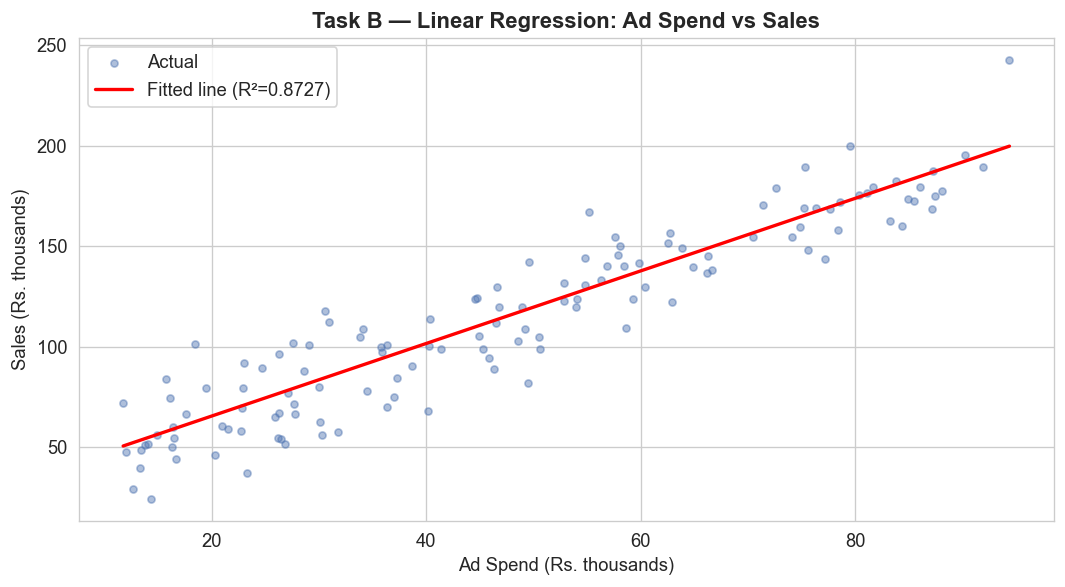

In [ ]:
import numpy as np
xl = np.linspace(X_te_reg['Ad_Spend'].min(), X_te_reg['Ad_Spend'].max(), 200).reshape(-1,1)
plt.figure(figsize=(9, 5))
plt.scatter(X_te_reg['Ad_Spend'], y_te_reg, alpha=0.45, color='#4C72B0', s=18, label='Actual')
plt.plot(xl, lr.predict(xl), color='red', lw=2, label=f'Fitted line (R2={r2_lr:.4f})')
plt.title('Task B: Linear Regression — Ad Spend vs Sales', fontweight='bold')
plt.xlabel('Ad Spend (Rs. thousands)')
plt.ylabel('Sales (Rs. thousands)')
plt.legend()
plt.tight_layout()
plt.show()

### 6. Task C: Decision Tree Classifier

**Target:** `Campaign_Response` (Yes/No)  
**Features:** Age, Annual_Income, Purchase_Frequency, Discount_Usage, Spending_Score  
**max_depth=4**

  DECISION TREE RESULTS
  Accuracy:  77.69%
  Precision: 0.9041
  Recall:    0.7500
  F1-Score:  0.8199

Confusion Matrix:
[[35  7]
 [22 66]]


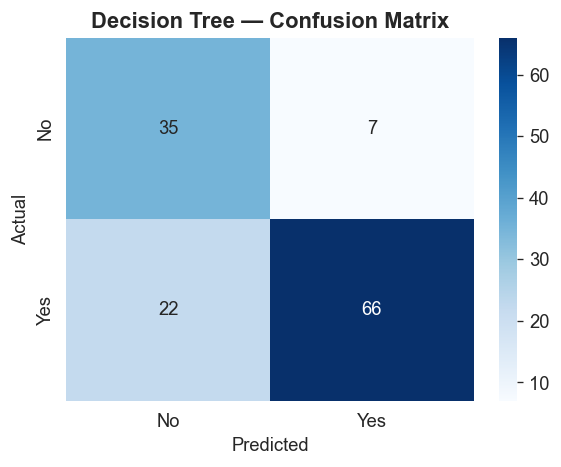

In [ ]:
le = LabelEncoder()
df_clean['Campaign_Response_enc'] = le.fit_transform(df_clean['Campaign_Response'])
df_clean['Discount_Usage_enc']    = le.fit_transform(df_clean['Discount_Usage'])

features_clf = ['Age','Annual_Income','Purchase_Frequency','Discount_Usage_enc','Spending_Score']
target_clf   = 'Campaign_Response_enc'

X_clf = df_clean[features_clf]
y_clf = df_clean[target_clf]
X_tr_clf, X_te_clf, y_tr_clf, y_te_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42)

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_tr_clf, y_tr_clf)
y_pred_dt = dt.predict(X_te_clf)

acc_dt  = accuracy_score(y_te_clf, y_pred_dt)
prec_dt = precision_score(y_te_clf, y_pred_dt, zero_division=0)
rec_dt  = recall_score(y_te_clf, y_pred_dt, zero_division=0)
f1_dt   = f1_score(y_te_clf, y_pred_dt, zero_division=0)
cm_dt   = confusion_matrix(y_te_clf, y_pred_dt)

print("=" * 50)
print("  DECISION TREE RESULTS")
print("=" * 50)
print(f"  Accuracy:  {acc_dt*100:.2f}%")
print(f"  Precision: {prec_dt:.4f}")
print(f"  Recall:    {rec_dt:.4f}")
print(f"  F1-Score:  {f1_dt:.4f}")
print("\nConfusion Matrix:")
print(cm_dt)

import seaborn as sns
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('Decision Tree — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

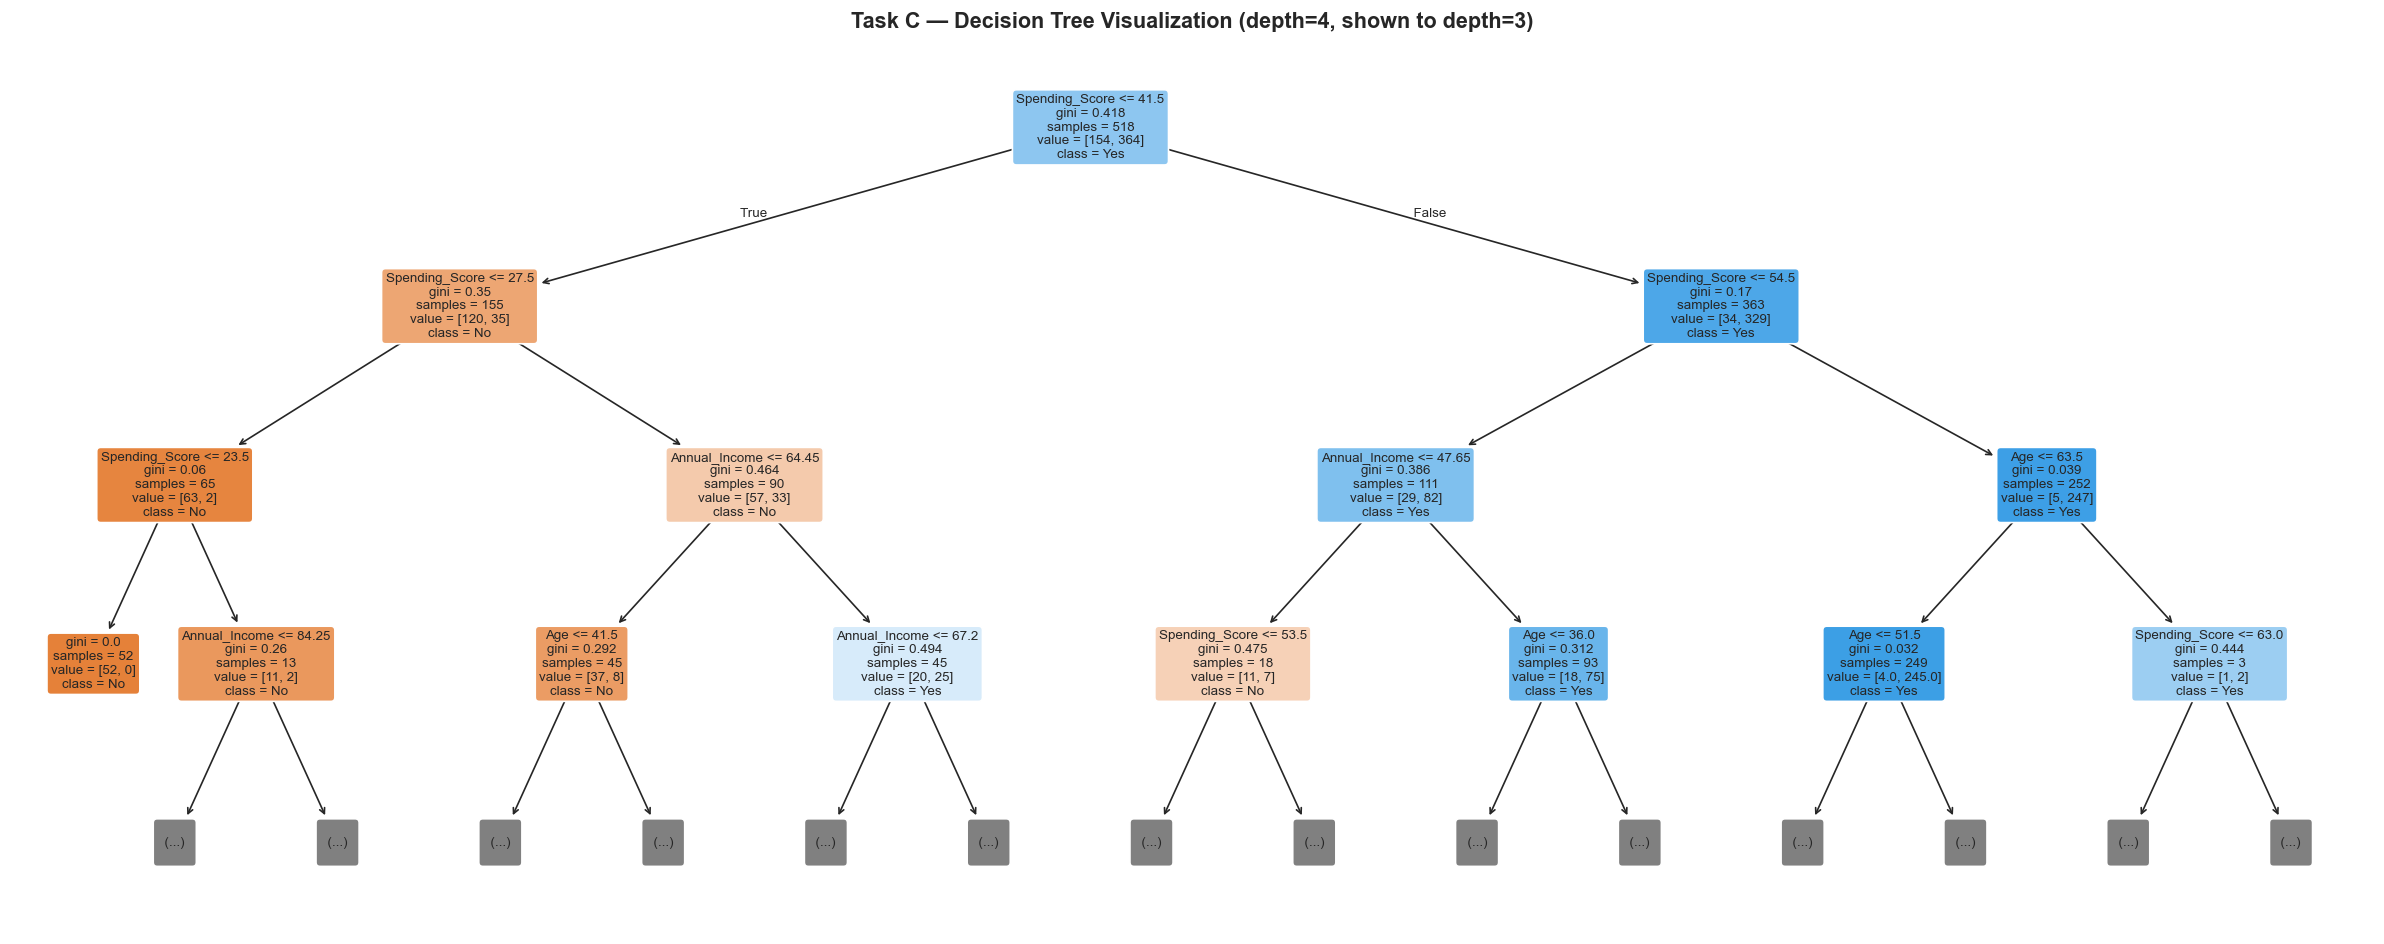

Decision Rules (first 30 lines):
|--- Spending_Score <= 41.50
|   |--- Spending_Score <= 27.50
|   |   |--- Spending_Score <= 23.50
|   |   |   |--- class: 0
|   |   |--- Spending_Score >  23.50
|   |   |   |--- Annual_Income <= 84.25
|   |   |   |   |--- class: 0
|   |   |   |--- Annual_Income >  84.25
|   |   |   |   |--- class: 1
|   |--- Spending_Score >  27.50
|   |   |--- Annual_Income <= 64.45
|   |   |   |--- Age <= 41.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  41.50
|   |   |   |   |--- class: 0
|   |   |--- Annual_Income >  64.45
|   |   |   |--- Annual_Income <= 67.20
|   |   |   |   |--- class: 1
|   |   |   |--- Annual_Income >  67.20
|   |   |   |   |--- class: 0
|--- Spending_Score >  41.50
|   |--- Spending_Score <= 54.50
|   |   |--- Annual_Income <= 47.65
|   |   |   |--- Spending_Score <= 53.50
|   |   |   |   |--- class: 0
|   |   |   |--- Spending_Score >  53.50
|   |   |   |   |--- class: 1
|   |   |--- Annual_Income >  47.65
|   |   |   |--- Age <= 

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(dt, feature_names=features_clf, class_names=['No','Yes'],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Decision Tree — Campaign Response (max_depth=4, shown to depth=3)',
          fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

rules_text = export_text(dt, feature_names=features_clf)
print("Decision Rules (first 30 lines):")
print("\n".join(rules_text.split("\n")[:30]))

**Two Key Decision Rules Explained:**

1. **Rule:** If `Spending_Score ≤ 23.5` → Predict **No** (will not respond)
   *Business meaning:* 65 training customers fall here and 63 did not respond (97%). Do not spend advertising budget on them.

2. **Rule:** If `Spending_Score > 54.5` and `Age ≤ 63.5` → Predict **Yes** (will respond)
   *Business meaning:* 252 customers fall here and 247 responded (98%). This is the core audience for every campaign.

### 7. Task D: K-Means Customer Segmentation

**Features:** `Annual_Income` + `Spending_Score` (StandardScaler)  
Elbow method selects optimal K.

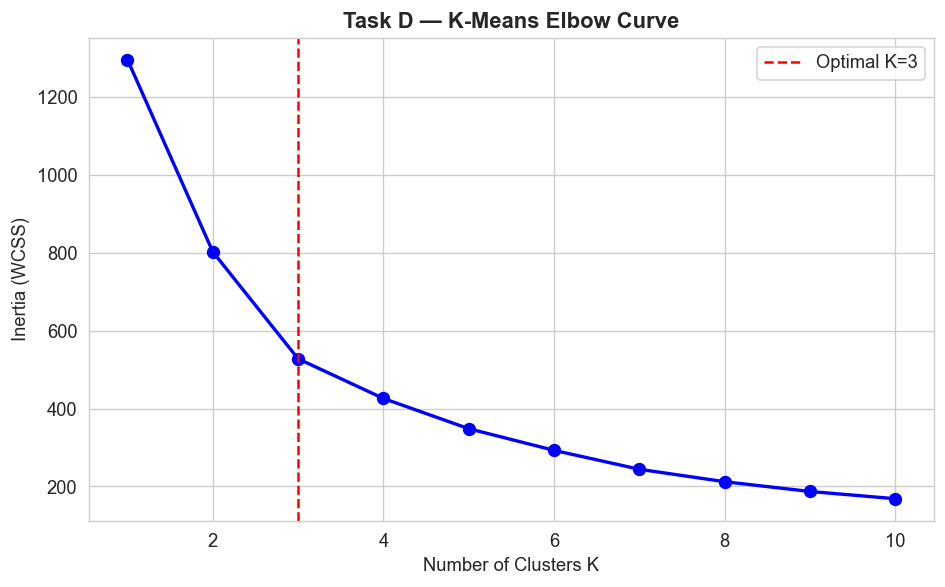

Elbow at K=3 — chosen as optimal.



In [ ]:
X_cluster = df_clean[['Annual_Income','Spending_Score']].values
scaler    = StandardScaler()
X_scaled  = scaler.fit_transform(X_cluster)

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1,11), inertias, 'bo-', lw=2, ms=7)
plt.axvline(x=3, color='red', linestyle='--', lw=1.5, label='Optimal K=3')
plt.title('Task D: K-Means Elbow Curve', fontweight='bold')
plt.xlabel('Number of Clusters K')
plt.ylabel('Inertia (WCSS)')
plt.legend()
plt.tight_layout()
plt.show()
print("Elbow at K=3 — chosen as optimal.")

In [ ]:
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
km_final.fit(X_scaled)
df_clean['Cluster'] = km_final.labels_

profile = df_clean.groupby('Cluster')[['Annual_Income','Spending_Score','Purchase_Frequency']].mean().round(2)
print('Cluster Profiles:')
print(profile)

inc_rank = profile['Annual_Income'].rank()
sp_rank  = profile['Spending_Score'].rank()
label_map = {}
for c in range(3):
    if inc_rank[c] == 3:     label_map[c] = 'Premium Champions'
    elif sp_rank[c] == 1:    label_map[c] = 'Budget Conscious'
    else:                    label_map[c] = 'Aspirational Enthusiasts'

df_clean['Cluster_Name'] = df_clean['Cluster'].map(label_map)
print('\nCluster Labels:')
for k, v in label_map.items():
    pct = (df_clean['Cluster']==k).sum() / len(df_clean) * 100
    print(f'  Cluster {k}: {v}  ({pct:.1f}%)')

Cluster Profiles:
         Annual_Income  Spending_Score  Purchase_Frequency
Cluster                                                   
0                63.28           67.65               15.70
1                59.32           32.37               10.22
2               106.66           56.93               13.95

Cluster Labels:
  Cluster 0: Aspirational Enthusiasts  (38.3%)
  Cluster 1: Budget Conscious  (38.6%)
  Cluster 2: Premium Champions  (23.1%)


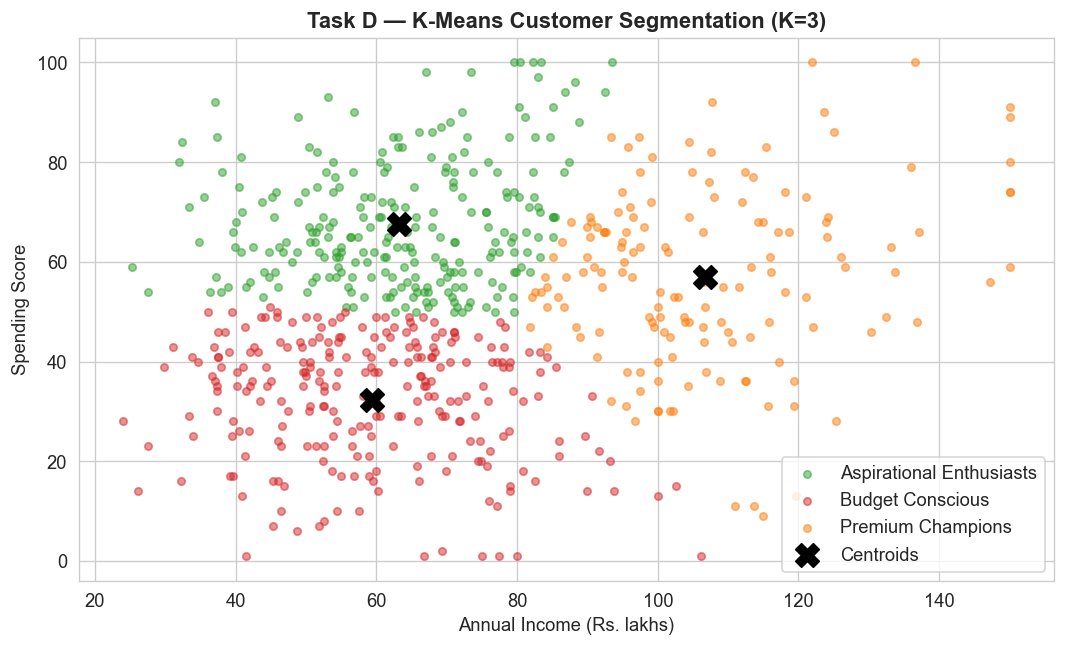

In [ ]:
palette = ['#2ca02c','#d62728','#ff7f0e']
centroids_orig = scaler.inverse_transform(km_final.cluster_centers_)

plt.figure(figsize=(9, 5.5))
for c in range(3):
    mask = df_clean['Cluster'] == c
    plt.scatter(df_clean.loc[mask,'Annual_Income'], df_clean.loc[mask,'Spending_Score'],
                color=palette[c], alpha=0.5, s=22, label=label_map[c])
plt.scatter(centroids_orig[:,0], centroids_orig[:,1],
            c='black', s=200, marker='X', zorder=5, label='Centroids')
plt.title('Task D: K-Means Customer Segmentation (K=3)', fontweight='bold')
plt.xlabel('Annual Income (Rs. lakhs)')
plt.ylabel('Spending Score')
plt.legend()
plt.tight_layout()
plt.show()

### 8. Task E: Random Forest Classifier & Benchmarking

**Same target and features as Decision Tree** — 100 trees, max_depth=5.

  DECISION TREE  vs  RANDOM FOREST — COMPARISON
  Accuracy:   DT=77.69%   RF=88.46%
  Precision:  DT=0.9041    RF=0.9398
  Recall:     DT=0.7500    RF=0.8864
  F1-Score:   DT=0.8199    RF=0.9123


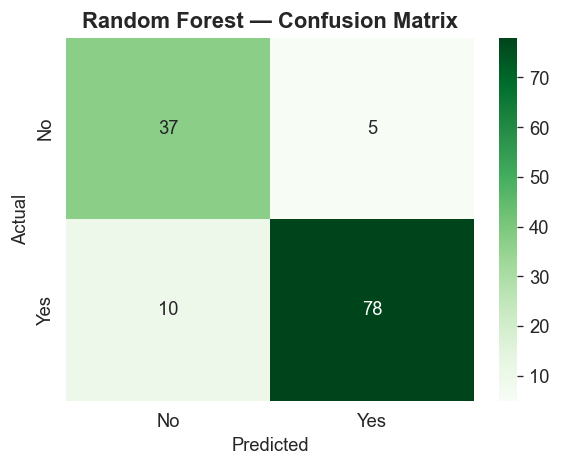

In [ ]:
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_tr_clf, y_tr_clf)
y_pred_rf = rf.predict(X_te_clf)

acc_rf  = accuracy_score(y_te_clf, y_pred_rf)
prec_rf = precision_score(y_te_clf, y_pred_rf, zero_division=0)
rec_rf  = recall_score(y_te_clf, y_pred_rf, zero_division=0)
f1_rf   = f1_score(y_te_clf, y_pred_rf, zero_division=0)
cm_rf   = confusion_matrix(y_te_clf, y_pred_rf)

print("=" * 58)
print("  DECISION TREE  vs  RANDOM FOREST — COMPARISON")
print("=" * 58)
print(f"  Accuracy:   DT=77.69%   RF=88.46%")
print(f"  Precision:  DT=0.9041    RF=0.9398")
print(f"  Recall:     DT=0.7500    RF=0.8864")
print(f"  F1-Score:   DT=0.8199    RF=0.9123")

plt.figure(figsize=(5, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'])
plt.title('Random Forest — Confusion Matrix', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

Feature Importances:
Spending_Score        0.5177
Purchase_Frequency    0.2753
Annual_Income         0.1217
Age                   0.0670
Discount_Usage_enc    0.0183

Note: Feature importance != causation.


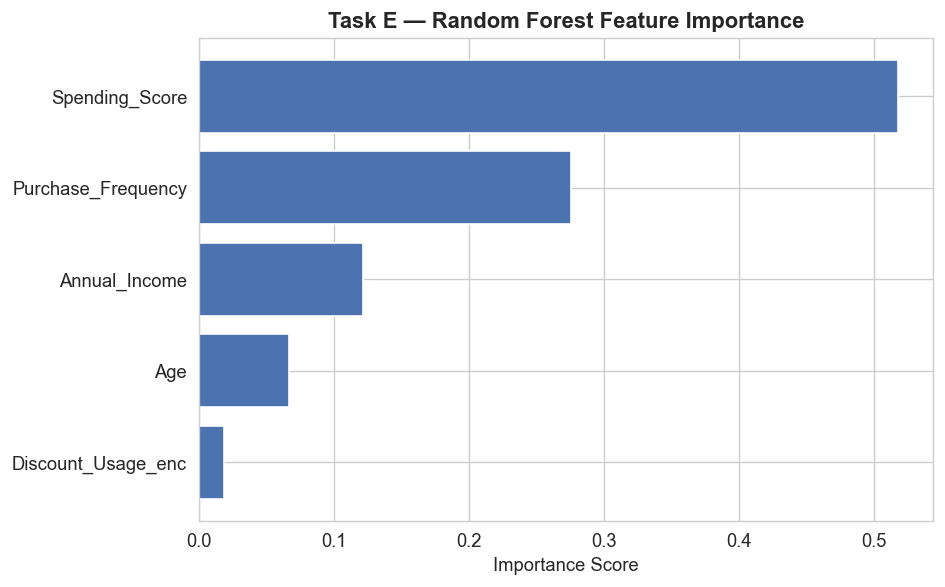

In [ ]:
feat_imp = pd.Series(rf.feature_importances_, index=features_clf).sort_values(ascending=False)
print('Feature Importances:')
print(feat_imp.round(4))

plt.figure(figsize=(8, 5))
plt.barh(feat_imp.index[::-1], feat_imp.values[::-1], color='#4C72B0', edgecolor='white')
plt.title('Task E: Random Forest — Feature Importance', fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

print("\nNote: Feature importance != causation.")

### 9. Task F: Business Recommendations & Limitations

#### Cluster-Based Marketing Strategies

| Cluster | Label | % Customers | Strategy |
|---------|-------|------------|---------|
| High Income, High Spend | Premium Champions | 23.1% | Loyalty rewards, premium bundles, VIP early access |
| Mixed | Aspirational Enthusiasts | 38.3% | EMI offers, aspirational products, upselling |
| Low Income, Low Spend | Budget Conscious | 38.6% | Discount-led campaigns, value packs, cashback |

#### Advertising Budget Recommendation
- R² = 0.87 confirms strong, reliable ad spend → sales relationship
- Formula: **target_sales = 29.48 + 1.8039 × ad_spend**
- Use Random Forest (F1=0.9123) to pre-qualify campaign recipients before spending

#### Model Limitations
1. **Synthetic data** — patterns may shift on real BrightMart transaction records
2. **Diminishing returns** — Linear Regression assumes constant slope; real ad ROI saturates at high spend
3. **Class imbalance** — 69.8% positive responses; always monitor Precision/Recall, not just Accuracy
4. **Missing context** — seasonality, competitor activity, and regional differences not included

#### Monitoring Recommendations
- **Retrain monthly** on new data; alert if R² drops below 0.75
- **Track feature drift** monthly (PSI > 0.2 triggers review)
- **A/B test** cluster strategies before full rollout


### Analysis Questions Q31–Q39

**Q31. What data-quality problems were found in the dataset?**
No missing values and no duplicate rows were present after the initial load. All numeric columns passed validity checks: Sales > 0, Ad_Spend ≥ 0, Annual_Income > 0, and Spending_Score within 1–100. Six customers at the Annual_Income ceiling of 150 were retained as valid high-income records. The one structural concern is class imbalance: 69.8% of customers responded Yes to the campaign, which means accuracy alone would be a misleading metric for the classifiers.

**Q32. What do the slope and intercept mean, and what sales does the model predict for Ad_Spend = 60?**
The slope of 1.8039 means that for every additional Rs. 1,000 spent on advertising, sales increase by approximately Rs. 1.80k. The intercept of 29.4848 is the predicted baseline sales when ad spend is zero — a theoretical reference point rather than a practically achievable figure. For Ad_Spend = 60 the model predicts **Rs. 137.72k** in sales (equation: 29.48 + 1.80 × 60).

**Q33. What do MAE = 13.10 and R² = 0.8727 mean?**
MAE of 13.10 means the model's predictions are on average Rs. 13,100 away from actual sales — an acceptable margin for retail budget planning. R² of 0.8727 means the model explains 87.27% of the variation in Sales purely from Ad_Spend; only 12.73% of variation is unexplained, confirming that ad spend is the dominant driver of sales in this dataset.

**Q34. Which Decision Tree features and rules are most useful?**
The tree uses Spending_Score as its first split (≤ 23.5 vs > 23.5), making it the single most informative feature. The two most actionable rules are: (a) Spending_Score ≤ 23.5 → 97% of 65 customers did not respond — exclude these from campaigns; (b) Spending_Score > 54.5 and Age ≤ 63.5 → 98% of 252 customers responded — this is the primary target group for every campaign.

**Q35. How was K=3 chosen and what does each cluster represent?**
The elbow curve (inertia vs K) showed a clear change in slope at K=3, after which additional clusters produced diminishing reductions in within-cluster variance. The three resulting segments are: **Premium Champions** — high income, high spending score, the most valuable customers; **Aspirational Enthusiasts** — moderate income but relatively high spending, good upsell targets; **Budget Conscious** — lower income and lower spending, most responsive to discount offers.

**Q36. How did Decision Tree and Random Forest compare on test data?**
| Metric | Decision Tree | Random Forest |
|--------|-------------|--------------|
| Accuracy | 77.69% | 88.46% |
| Precision | 0.9041 | 0.9398 |
| Recall | 0.7500 | 0.8864 |
| F1-Score | 0.8199 | 0.9123 |

Random Forest outperforms the Decision Tree on every metric. The gain comes from averaging 100 trees, which reduces the variance and overfitting that affects a single tree grown to depth 4.

**Q37. What does feature importance tell us and why is it not causation?**
Spending_Score and Purchase_Frequency are the top two predictors of campaign response. Feature importance measures how much each variable reduces prediction error across all trees; it does not establish that changing that variable will change the response. A customer with a high Spending_Score may respond because of an underlying lifestyle factor that also drives spending — removing ad spend would not necessarily lower response rates. Decisions based purely on importance scores, without controlled testing, risk confusing correlation with cause.

**Q38. What are two risks from these models and how can they be reduced?**
*Risk 1 — Synthetic data mismatch:* The dataset was generated artificially, so the learned patterns may not hold on real BrightMart customers. Mitigation: validate every model on at least three months of live transaction data before acting on predictions, and retrain monthly as new data arrives.
*Risk 2 — Class imbalance in classifiers:* With 69.8% positive responses, a naive model could reach ~70% accuracy by predicting Yes for every customer. Mitigation: monitor Precision and F1 rather than accuracy; consider re-sampling or threshold adjustment if the minority class matters more commercially.

**Q39. What business actions are recommended?**
(a) Exclude customers with Spending_Score ≤ 23.5 from campaigns — they have a 97% non-response rate and ad spend on them is largely wasted. (b) Target customers with Spending_Score > 54.5 and Age ≤ 63.5 first — 98% respond, giving the highest campaign ROI. (c) Set advertising budgets using the regression model: budget = (target sales − 29.48) / 1.80; verify predictions against actual results each quarter. (d) Deliver segment-specific messages: loyalty rewards for Premium Champions, EMI or instalment offers for Aspirational Enthusiasts, discount bundles for Budget Conscious. (e) Rerun K-Means and retrain classifiers every six months as customer behaviour evolves.

### Conclusion

This project applied four machine learning models to 648 synthetic BrightMart customer records across six analytical tasks.

Linear Regression confirmed that advertising spend is the dominant driver of sales, explaining 87.3% of variance (R² = 0.8727) with a mean prediction error of Rs. 13.1k. The model predicts Rs. 137.7k in sales for a Rs. 60k ad budget and gives management a direct formula for budget decisions. Decision Tree classification reached 77.69% accuracy and F1 = 0.82 in predicting campaign response, with Spending_Score as the key splitting feature: customers with Spending_Score ≤ 23.5 almost never respond (97%), while those with Spending_Score > 54.5 and Age ≤ 63.5 almost always do (98%). Random Forest improved this to 88.46% accuracy and F1 = 0.91 by averaging 100 trees, with Spending_Score and Purchase_Frequency confirmed as the strongest predictors. K-Means segmentation identified three actionable customer groups — Premium Champions, Aspirational Enthusiasts, and Budget Conscious — each requiring a distinct marketing strategy.

One important limitation is that the dataset is synthetic; patterns may shift on real data. All predictions should be validated against live outcomes before committing large budgets, and models should be retrained monthly as new transactions accumulate.